# Unified CEBRA: pooling recordings with different neurons

Each recording samples a few neurons from a population. Unified CEBRA
(Benquet, Mirzaei, Schneider & Mathis 2026) trains **one** encoder on the
neurons of **every** recording, by lining the recordings up on a label they
share, such as position. Every neuron then has a signed contribution to the
population code, and those contributions are on **one scale across
recordings and animals**.

This notebook uses five simulated animals from `raphael.toy`. Each animal
has its own 20 neurons: 12 place cells, 4 head-direction cells and 4 untuned
cells. Because the simulation is known, every result below can be checked
against the truth.

1. Fit one encoder to all five animals, with position as the shared label.
2. Decode position, and compare with CEBRA fitted to each animal alone.
3. Run the control: shuffle the activity, keep the labels, and the
   information disappears.
4. Make the attribution map: which neurons drive the readout of x and y?
5. Check it is reproducible: fit a second run from a different seed.

**Install:** the `cebra` extra (`uv sync --extra cebra` in Raphael, or
`"raphael[cebra]"` in a project). **Hardware:** a GPU. On an Apple-silicon Mac
the whole notebook takes about 15 minutes. On a CPU it is roughly 20 times
slower, so lower `ITERATIONS` to try it out. See docs/ml.md.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from raphael import ml, style, toy
from raphael.ml import unified

warnings.filterwarnings('ignore')
style.use()

ITERATIONS = 2000           # training steps; 5000+ for real data
ANIMALS = 5

## The data

Ten minutes of foraging per animal in a 1 m arena, binned at 100 ms during
movement. Each animal has a different `tuning_seed`, so a different set of
neurons with different place fields. The shared label is position (x, y,
in cm), which every recording defines the same way.

In [2]:
neural, labels, truth = [], [], []
for animal in range(ANIMALS):
    s = toy.session(duration=600, seed=10 + animal, tuning_seed=100 + animal, n_place=12, n_hd=4,
                    n_speed=0, n_theta=0, n_event=0, n_untuned=4)
    t, counts = ml.bin_counts(s['spikes'], binsize=0.1, ep=s['behaviour']['moving'])
    neural.append(counts)
    labels.append(ml.behaviour_at(s['behaviour'], ['P_x', 'P_y'], t))
    truth.append(s['tuning'].query("modality == 'spikes'").set_index('id'))

truth = pd.concat({i: t for i, t in enumerate(truth)}, names=['recording', 'neuron'])
train, test = unified.split(neural, labels, test_fraction=0.2)   # last 20% of each recording held out
print([x.shape for x in neural], '(bins x neurons, per animal)')

[(5492, 20), (5415, 20), (5365, 20), (5403, 20), (5386, 20)] (bins x neurons, per animal)


## One encoder for every animal

At each training step, one recording is the reference. Every other
recording contributes its activity at the timepoint where its position is
nearest. The matched activities are concatenated into one pseudo-population
of all 100 neurons, and one encoder embeds it with CEBRA's contrastive
objective.

The labels only choose which timepoints are pooled. They are never an input
to the encoder.

100 neurons from 5 recordings, on mps; goodness of fit 2.05 bits


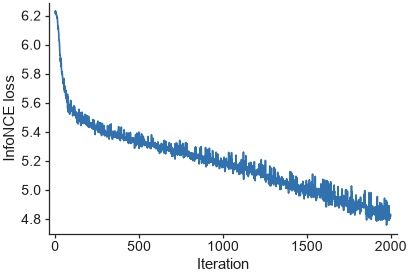

In [3]:
model = unified.Unified(max_iterations=ITERATIONS, output_dimension=8, seed=0).fit(*train)
print(f'{sum(model.n_neurons_)} neurons from {len(neural)} recordings, on {model.device_}; '
      f'goodness of fit {model.goodness_of_fit:.2f} bits')

fig, ax = plt.subplots(figsize=(3, 2))
ax.plot(model.loss_)
ax.set(xlabel='Iteration', ylabel='InfoNCE loss')
plt.show()

The embedding along one animal's held-out timeline is shown below. It is a
map of the arena, made by the pooled population. The plot shows two
principal components of the 8-dimensional embedding, coloured by the
animal's true position.

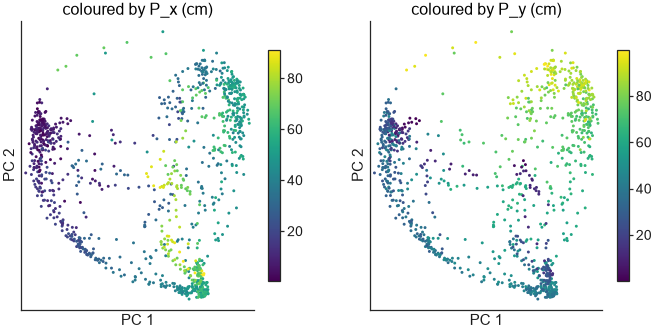

In [4]:
from sklearn.decomposition import PCA

z = model.transform(*test, target=0)
pcs = PCA(2).fit_transform(z)
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.5))
for ax, name in zip(axes, ['P_x', 'P_y']):
    sc = ax.scatter(pcs[:, 0], pcs[:, 1], c=test[1][0][name], s=2, cmap='viridis')
    ax.set(title=f'coloured by {name} (cm)', xticks=[], yticks=[], xlabel='PC 1', ylabel='PC 2')
    fig.colorbar(sc, ax=ax, shrink=0.8)
plt.show()

## Decoding position: pooled vs one animal at a time

A k-nearest-neighbour decoder is fitted on each animal's training embedding
and scored on its held-out block, as in the paper. The baseline is CEBRA
fitted to that animal's own 20 neurons, with the same settings and the same
decoder.

Unified CEBRA uses the labels at inference too, to pick each other
animal's matching timepoints. Its score therefore measures how much
position the **pooled population** carries along that animal's timeline. It
is not a prediction from that animal's neurons alone. The next section shows
that the labels alone carry nothing.

In [5]:
pooled = unified.decode(model, train, test, train[1], test[1])
single = []
for i in range(ANIMALS):
    one_train, one_test = ([train[0][i]], [train[1][i]]), ([test[0][i]], [test[1][i]])
    alone = unified.Unified(max_iterations=ITERATIONS, output_dimension=8, seed=0).fit(*one_train)
    single.append(unified.decode(alone, one_train, one_test, one_train[1], one_test[1]).iloc[0])
single = pd.DataFrame(single, index=pooled.index)

scores = pd.concat({'one animal (CEBRA)': single, 'all animals (Unified CEBRA)': pooled}, axis=1)
scores.round(2)

one animal (CEBRA)                  all animals (Unified CEBRA)  \
                          r2 median_abs_error                          r2   
recording                                                                   
0                       0.27             7.09                        0.91   
1                       0.61             6.46                        0.93   
2                       0.39             7.14                        0.92   
3                       0.56             7.19                        0.88   
4                       0.16             9.33                        0.87   

                            
          median_abs_error  
recording                   
0                     3.09  
1                     2.96  
2                     3.07  
3                     3.50  
4                     3.82

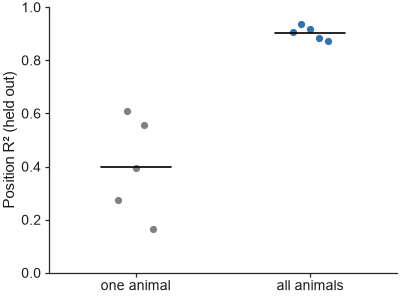

In [6]:
fig, ax = plt.subplots(figsize=(3, 2.3))
for x, (name, colour) in enumerate([('one animal (CEBRA)', 'grey'),
                                    ('all animals (Unified CEBRA)', 'C0')]):
    r2 = scores[name]['r2']
    ax.scatter(np.full(len(r2), x) + np.linspace(-0.1, 0.1, len(r2)), r2, color=colour, s=12)
    ax.plot([x - 0.2, x + 0.2], [r2.mean()] * 2, color='k')
ax.set(xticks=[0, 1], xticklabels=['one animal', 'all animals'], ylabel='Position R² (held out)',
       ylim=(0, 1), xlim=(-0.5, 1.5))
plt.show()

## Control: the labels alone carry nothing

Each neuron's held-out activity is shuffled in time, and the labels and the
matching are kept exactly as they were. If matching on position were enough
to make the embedding look like position, decoding would survive the
shuffle. It doesn't.

In [7]:
shuffled = (unified.shuffle_neurons(test[0]), test[1])
control = unified.decode(model, train, shuffled, train[1], test[1])
pd.DataFrame({'intact R²': pooled['r2'], 'shuffled R²': control['r2']}).round(2)

,intact R²,shuffled R²
recording,,
0,0.91,-0.38
1,0.93,-0.38
2,0.92,-0.35
3,0.88,-0.13
4,0.87,-0.28


## Which neurons carry position? The attribution map

The encoder's Jacobian is chained with a linear (ridge) readout of x and y
from the embedding. This gives every neuron a signed attribution
$M = J^\top W$: how far a change in its activity moves the readout of each
feature. The map is invariant to the rotation that relates independently
trained runs. All 100 neurons are on one scale, whichever animal they came
from.

Two checks against the truth:
- **Place cells carry position.** Head-direction and untuned cells should
  have attributions near zero.
- **The sign points to the field.** A place cell firing pushes the readout
  towards its field, so a cell's x attribution should follow its field's x
  centre, and likewise for y.

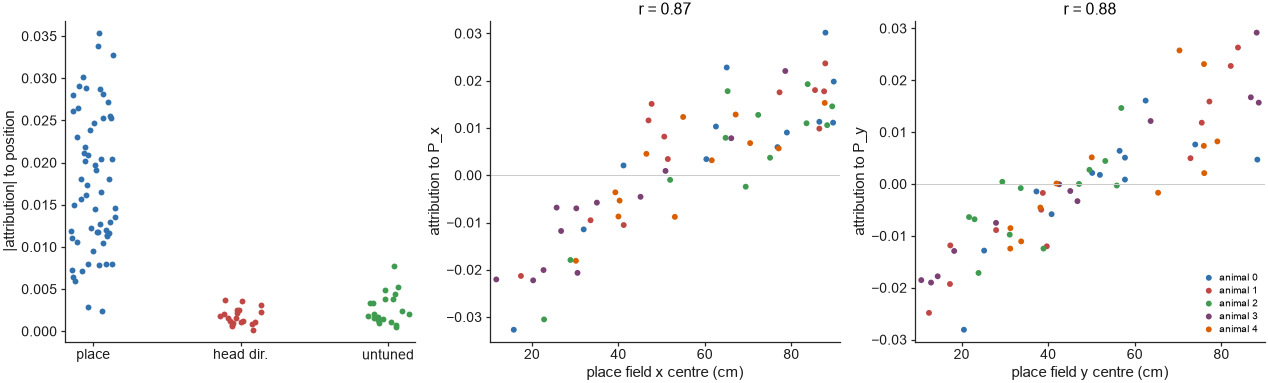

In [8]:
M = unified.attribution(model, train, train[1])
M['kind'] = truth['kind'].reindex(M.index).to_numpy()
M['magnitude'] = np.hypot(M['P_x'], M['P_y'])
place = M['kind'] == 'place'
fields = truth.reindex(M.index)

fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.6), layout='constrained')
kinds = ['place', 'head_direction', 'untuned']
for x, kind in enumerate(kinds):
    m = M.loc[M['kind'] == kind, 'magnitude']
    axes[0].scatter(np.full(len(m), x) + np.random.default_rng(x).uniform(-0.15, 0.15, len(m)), m,
                    s=8, color=f'C{x}')
axes[0].set(xticks=range(3), xticklabels=['place', 'head dir.', 'untuned'],
            ylabel='|attribution| to position')
for ax, name, centre in [(axes[1], 'P_x', 'x'), (axes[2], 'P_y', 'y')]:
    for rec in range(ANIMALS):
        sel = place & (M.index.get_level_values('recording') == rec)
        ax.scatter(fields.loc[sel, centre], M.loc[sel, name], s=8, label=f'animal {rec}')
    r = np.corrcoef(fields.loc[place, centre], M.loc[place, name])[0, 1]
    ax.axhline(0, color='0.8', lw=0.5)
    ax.set(xlabel=f'place field {centre} centre (cm)', ylabel=f'attribution to {name}',
           title=f'r = {r:.2f}')
axes[2].legend(fontsize=5, loc='lower right')
plt.show()

### Where does a neuron push the readout?

The time-resolved map $M(t)$ gives each neuron's (x, y) attribution at
every moment of its own animal's timeline. If the encoder has learnt what a
place cell means, a burst from that cell should pull the decoded position
towards its field, from wherever the animal is.

- **Top:** three place cells, one from each of three animals. Each has its
  rate map, with arrows showing the mean attribution at each part of the
  arena (+ marks the true field centre).
- **Bottom:** for every place cell, the cosine between $M(t)$ and the
  direction from the animal to the field, averaged over time. The cosine is
  1 when the cell always pulls towards its field, and 0 for unrelated
  directions.

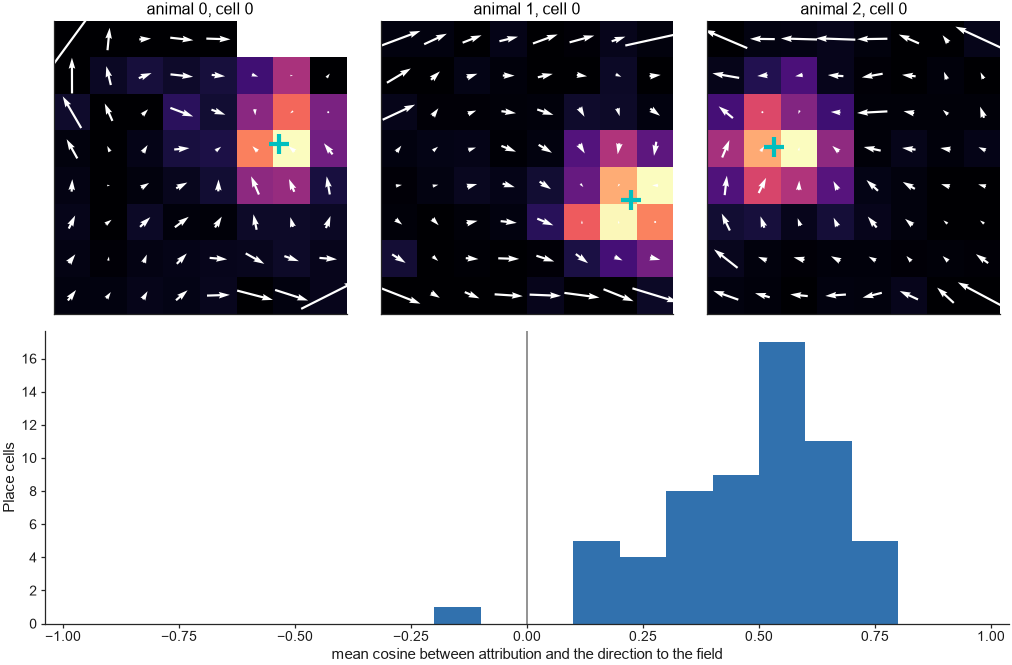

98% of place cells pull the readout towards their field on average (median cosine 0.52)


In [9]:
edges = np.linspace(0, 100, 9)
centres = (edges[:-1] + edges[1:]) / 2


def arena_mean(x, y, values):
    total, _, _ = np.histogram2d(x, y, [edges, edges], weights=values)
    n, _, _ = np.histogram2d(x, y, [edges, edges])
    return np.where(n > 5, total / np.maximum(n, 1), np.nan).T


neuron_order = list(M.index)
towards = []
fig = plt.figure(figsize=(7, 4.6))
for rec in range(ANIMALS):
    Mt = unified.attribution(model, train, train[1], over_time=True, target=rec)    # T x N x 2
    pos = train[1][rec][['P_x', 'P_y']].to_numpy()
    for neuron in M[place].xs(rec, level='recording').index:
        j = neuron_order.index((rec, neuron))
        field = fields.loc[(rec, neuron), ['x', 'y']].to_numpy(float)
        to_field = field - pos
        cos = (Mt[:, j] * to_field).sum(1) / (np.linalg.norm(Mt[:, j], axis=1)
                                             * np.linalg.norm(to_field, axis=1) + 1e-12)
        towards.append(cos.mean())
        if rec < 3 and neuron == M[place].xs(rec, level='recording').index[0]:
            ax = fig.add_subplot(2, 3, rec + 1)
            rate = arena_mean(pos[:, 0], pos[:, 1], train[0][rec][neuron].to_numpy() / 0.1)
            ax.imshow(rate, origin='lower', extent=(0, 100, 0, 100), cmap='magma')
            u = arena_mean(pos[:, 0], pos[:, 1], Mt[:, j, 0])
            v = arena_mean(pos[:, 0], pos[:, 1], Mt[:, j, 1])
            gx, gy = np.meshgrid(centres, centres)
            ax.quiver(gx, gy, u, v, color='w', angles='xy', pivot='middle')
            ax.plot(*field, '+', color='c', ms=10, mew=2)
            ax.set(xticks=[], yticks=[], title=f'animal {rec}, cell {neuron}')

ax = fig.add_subplot(2, 1, 2)
ax.hist(towards, bins=np.linspace(-1, 1, 21), color='C0')
ax.axvline(0, color='0.5', lw=0.8)
ax.set(xlabel='mean cosine between attribution and the direction to the field',
       ylabel='Place cells')
fig.tight_layout()
plt.show()
print(f'{np.mean(np.array(towards) > 0):.0%} of place cells pull the readout towards their field '
      f'on average (median cosine {np.median(towards):.2f})')

## Is it reproducible?

A second encoder is fitted with a different seed, and compared with the
first in two ways:
- **embeddings:** how well a linear map takes one run's embedding onto the
  other's (R²);
- **attributions:** the rank correlation of the two runs' attribution
  magnitudes, across all neurons.

Do this on real data before interpreting a map: a map that changes between
seeds can't be trusted.

In [10]:
second = unified.Unified(max_iterations=ITERATIONS, output_dimension=8, seed=1).fit(*train)
M2 = unified.attribution(second, train, train[1])
embedding_r2 = [unified.consistency(model.transform(*test, target=i), second.transform(*test, target=i))
                for i in range(ANIMALS)]
rho = spearmanr(M['magnitude'], np.hypot(M2['P_x'], M2['P_y'])).statistic
print(f'embedding consistency across seeds: R² {np.mean(embedding_r2):.2f} (mean over animals)')
print(f'attribution magnitude, rank correlation across seeds: {rho:.2f}')

embedding consistency across seeds: R² 0.98 (mean over animals)
attribution magnitude, rank correlation across seeds: 0.96


## Saving and loading

A fitted model saves to one file: its weights, its settings, the label
scaling, and each recording's neuron names.

In [11]:
import tempfile
from pathlib import Path

path = model.save(Path(tempfile.mkdtemp()) / 'unified_cebra.pt')
again = unified.Unified.load(path)
np.allclose(again.transform(*test, target=0), model.transform(*test, target=0), atol=1e-5)

True

## On real data

- **Choosing the labels is a modelling decision, like choosing a GLM's
  regressors.** The labels decide which relationships you can test. They
  don't impose structure: labels unrelated to the activity give an
  unstructured embedding. Every recording must define them the same way,
  e.g. position in arena cm, time in trial or a stimulus feature.
  Categorical variables go in as extra one-hot columns.
- **Partial coverage is tolerated.** In the paper, a shared map was still
  recovered when each animal visited only part of the track.
- **Two things from the paper aren't here yet.** CEBRA 0.6.1's unified
  solver doesn't have the stochastic neuron/time masking the paper used
  for decoding, or the Jacobian regularisation it used for the
  visual-cortex attribution maps. Check a map's reproducibility across
  seeds, as above.
- **Binning:** `ml.bin_counts` for spikes. dF/F or photometry traces go in
  as they are, resampled to common bins.